# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170327      # <-- your full roll number
NAME = "Hitanshi Antil"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170327   Name: Hitanshi Antil   Fingerprint: EF9C08C7   Tickets: 14

Ticket_ID                                                                               Ticket_Text
      T01                                               The state-of-the-art lab (Lab-3) is closed.
      T02       Printer keeps asking for login before the assignment deadline. It worked yesterday.
      T03                                                               The file is 95.5% uploaded.
      T04                 I couldn't connect to the server on my laptop. Is there another solution?
      T05                              The email was working yesterday. I have tried several times!
      T06                   Python has stopped syncing when connected to campus Wi-Fi. Please help.
      T07 I keep getting logged out of the projector during the lab. The same problem occurs again.
      T08     I tried restarting the password when I use mobile hotspot. I don't know what changed.
      T09     

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [9]:

# Create an empty list to store the results
results = []

# Process every ticket
for i, row in df.iterrows():
    text = row["Ticket_Text"]
    data = process_ticket(text)

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(data["sentences"]),
        "Tokens": len(data["tokens"]),
        "Punctuation": len(data["punct"]),
        "Stopwords": len(data["stops"]),
        "Unique Tokens": len(set(data["tokens"])),
        "Final Tokens": data["final"]
    })

# Convert results into a DataFrame
result_df = pd.DataFrame(results)

# Calculate total values
total = {
    "Ticket_ID": "TOTAL",
    "Sentences": result_df["Sentences"].sum(),
    "Tokens": result_df["Tokens"].sum(),
    "Punctuation": result_df["Punctuation"].sum(),
    "Stopwords": result_df["Stopwords"].sum(),
    "Unique Tokens": "-",
    "Final Tokens": "-"
}

# Add the total row
result_df.loc[len(result_df)] = total

# Display the table
print(result_df.to_string(index=False))


Ticket_ID  Sentences  Tokens  Punctuation  Stopwords Unique Tokens                                                             Final Tokens
      T01          1       9            3          2             9                                   [state-of-the-art, lab, lab-3, closed]
      T02          2      14            2          4            13 [printer, keeps, asking, login, assignment, deadline, worked, yesterday]
      T03          1       7            2          2             7                                                   [file, 95.5, uploaded]
      T04          2      16            2          7            16                 [could, n't, connect, server, laptop, another, solution]
      T05          2      12            2          4            12                       [email, working, yesterday, tried, several, times]
      T06          2      13            2          3            12       [python, stopped, syncing, connected, campus, wi-fi, please, help]
      T07          2

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens may not be complete words, such as `n't`, `'s`, and `ca`. These tokens come from contractions. The word tokenizer splits contractions into smaller parts, and the preprocessing pipeline removes punctuation and stopwords but does not combine these parts back into complete words.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [12]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re

# Function to extract and replace patterns
def analyze_text(text):
    # Words longer than 5 letters
    long_words = re.findall(r'\b[A-Za-z]{6,}\b', text)

    # Numbers, including decimals and versions
    numbers = re.findall(r'\b\d+(?:\.\d+)*\b', text)

    # Capitalized words
    capitalized = re.findall(r'\b[A-Z][a-zA-Z]*\b', text)

    # Words starting with a vowel
    vowels = re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', text)

    # Replace URLs first
    cleaned = re.sub(
        r'https?://\S+|www\.\S+',
        '<URL>',
        text
    )

    # Replace email addresses
    cleaned = re.sub(
        r'\b[\w.-]+@[\w.-]+\.[a-zA-Z]{2,}\b',
        '<EMAIL>',
        cleaned
    )

    # Replace phone numbers
    cleaned = re.sub(
        r'(?<!\w)(?:\+91[\s-]*)?(?:\d[\s-]*){10}(?!\w)|\b\d{4}-\d{3}-\d{4}\b',
        '<PHONE>',
        cleaned
    )

    return long_words, numbers, capitalized, vowels, cleaned


# Run on the given TEST_LINES
print("RESULTS FOR TEST_LINES")

for line in TEST_LINES:
    print("\nOriginal:", line)

    long_words, numbers, capitalized, vowels, cleaned = analyze_text(line)

    print("Long words:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized)
    print("Words starting with vowels:", vowels)
    print("After replacement:", cleaned)


# Run on your actual dataset
print("\n\nRESULTS FOR YOUR TICKETS")

for i, row in df.iterrows():
    print("\n", row["Ticket_ID"])

    long_words, numbers, capitalized, vowels, cleaned = analyze_text(
        row["Ticket_Text"]
    )

    print("Long words:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized)
    print("Words starting with vowels:", vowels)
    print("After replacement:", cleaned)


RESULTS FOR TEST_LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Long words: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Words starting with vowels: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
After replacement: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Long words: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Words starting with vowels: ['or', 'is']
After replacement: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Long words: []
Numbers: ['5.30']
Capitalized words: ['The']
Words starting with vowels: ['

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Some capitalized words occur at the beginning of sentences, so they are capitalized only because of their position. Other words, such as names and abbreviations, may be capitalized for other reasons. The exact number can be found by checking the capitalized words in the output.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [13]:

from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = r"""(?ix)
    https?://[^\s<>]+
  | www\.[^\s<>]+
  | [A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}
  | (?:\+\d{1,3}[ -]?)?(?:\(?\d{3,5}\)?[ -]?)\d{3,5}[ -]?\d{3,5}
  | \d+(?:\.\d+)+
  | [A-Z]+(?:'[A-Z]+)+
  | [A-Z]+(?:-[A-Z]+)+
  | [A-Z]+
  | \d+(?:,\d{3})*(?:%?)
  | [^\w\s]
"""

my_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

# Test on the given TEST_LINES
print("--- TEST_LINES ---")
for line in TEST_LINES:
    print("\nText:", line)
    print("Custom:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

# Compare tokenization of all tickets
print("\n--- TICKETS ---")
different_tickets = []

for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])

    if [x.lower() for x in custom] != [x.lower() for x in standard]:
        different_tickets.append(row["Ticket_ID"])

    print("\n", row["Ticket_ID"])
    print("Custom:", custom)
    print("word_tokenize:", standard)

print("\nTickets tokenized differently:",
      len(different_tickets), "/", len(df))
print("Ticket IDs:", different_tickets)


--- TEST_LINES ---

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+', '91', '98765', '43210', ',', '+', '91', '-', '98765', '-', '43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in a

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The custom tokenizer keeps special text patterns together, whereas `word_tokenize()` may split them into multiple tokens.

1. **Contractions:** `isn't` may be split into `is` and `n't` by `word_tokenize()`.
2. **Hyphenated words:** `state-of-the-art` may be split at the hyphens, while the custom tokenizer keeps it together.
3. **Numbers and versions:** `2.0.1` is kept as one token by the custom tokenizer, but the standard tokenizer may split it.

Emails, URLs, and phone numbers are also designed to remain single tokens. The exact number of tickets that differ is printed by the code above.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:

from nltk.stem import (
    PorterStemmer,
    LancasterStemmer,
    RegexpStemmer,
    WordNetLemmatizer
)
from nltk import pos_tag
import pandas as pd
import nltk

# Download required NLTK resources if needed
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Remove common endings: ing, ed, and s
regex_stemmer = RegexpStemmer(r"ing$|ed$|s$", min=4)

lemmatizer = WordNetLemmatizer()

# Convert NLTK POS tags into WordNet POS tags
def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"       # Adjective
    elif tag.startswith("V"):
        return "v"       # Verb
    elif tag.startswith("N"):
        return "n"       # Noun
    elif tag.startswith("R"):
        return "r"       # Adverb
    return "n"

# Get unique final tokens from your tickets
unique_final = sorted(set(final_tokens))

# Assign POS tags to the words
pos_tags = dict(pos_tag(unique_final))

comparison = []

for word in unique_final:
    tag = pos_tags[word]

    comparison.append({
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regex_stemmer.stem(word),
        "POS tag": tag,
        "WordNet lemma": lemmatizer.lemmatize(
            word, wordnet_pos(tag)
        )
    })

comparison_df = pd.DataFrame(comparison)

# Show only words where at least two methods differ
columns = ["Porter", "Lancaster", "Regexp", "WordNet lemma"]

changed = comparison_df[
    comparison_df[columns].nunique(axis=1) > 1
]

display(changed.reset_index(drop=True))

print(
    "Regexp rule: removes ing, ed, or s from words "
    "of at least 4 characters."
)
print(
    "Justification: these suffixes occur in ticket words "
    "such as 'working', 'uploaded', and plural forms."
)


,Word,Porter,Lancaster,Regexp,POS tag,WordNet lemma
0,access,access,access,acces,NN,access
1,another,anoth,anoth,another,DT,another
2,assignment,assign,assign,assignment,NN,assignment
3,campus,campu,camp,campu,NN,campus
4,changed,chang,chang,chang,VBD,change
5,closed,close,clos,clos,JJ,closed
6,computer,comput,comput,computer,NN,computer
7,deadline,deadlin,deadlin,deadline,VB,deadline
8,file,file,fil,file,NN,file
9,getting,get,get,gett,VBG,get


Regexp rule: removes ing, ed, or s from words of at least 4 characters.
Justification: these suffixes occur in ticket words such as 'working', 'uploaded', and plural forms.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* **Over-stemming:** This happens when a stemmer removes too much of a word and produces an incorrect or unnatural stem. Lancaster Stemmer can sometimes be more aggressive than Porter Stemmer.

**Under-stemming:** This happens when related words are not reduced to the same stem.

**Comparison:** Porter and Lancaster use different stemming rules, while Regexp Stemmer removes only the suffixes specified in its pattern. WordNet Lemmatizer uses linguistic information and POS tags to find a meaningful base form. The results therefore differ for some words in the dataset.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1: All tokens,176,104,0.5909
1,S2: Without punctuation,148,97,0.6554
2,S3: Final tokens,86,69,0.8023
3,S4: Porter stemming,86,64,0.7442


Top 10 words of S1:
[('.', 22), ('the', 14), ('i', 7), ('is', 5), ('it', 4), ('to', 4), ('yesterday', 3), ('file', 3), ('has', 3), ('lab', 2)]

Top 10 words of S3:
[('yesterday', 3), ('file', 3), ('lab', 2), ('worked', 2), ("n't", 2), ('another', 2), ('tried', 2), ('python', 2), ('stopped', 2), ('syncing', 2)]


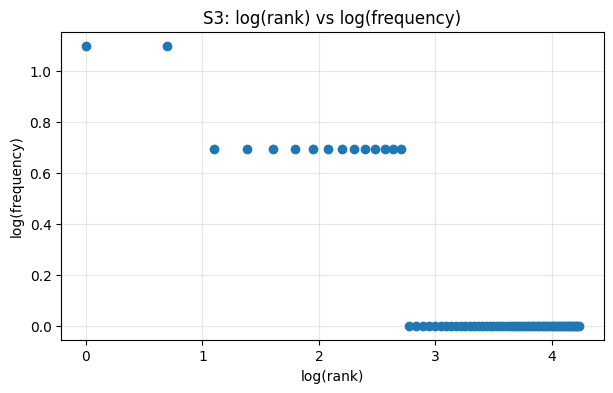


Top 5 bigrams of S1:
[(('.', 'i'), 6), (('.', 'it'), 3), (('yesterday', '.'), 3), (('.', 'the'), 3), (('the', 'file'), 3)]

Top 5 bigrams of S3:
[(('worked', 'yesterday'), 2), (('stopped', 'syncing'), 2), (('uploading', 'file'), 2), (('state-of-the-art', 'lab'), 1), (('lab', 'lab-3'), 1)]


In [15]:

from collections import Counter
from nltk.util import bigrams
import matplotlib.pyplot as plt
import numpy as np

# Create the four token sets
S1 = all_tokens
S2 = [t for t in S1 if not is_punct(t)]
S3 = final_tokens
S4 = [porter.stem(t) for t in S3]

# Calculate total tokens, unique tokens and TTR
def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        "Corpus": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(ttr, 4)
    }

stats_df = pd.DataFrame([
    corpus_stats("S1: All tokens", S1),
    corpus_stats("S2: Without punctuation", S2),
    corpus_stats("S3: Final tokens", S3),
    corpus_stats("S4: Porter stemming", S4)
])

display(stats_df)

# Top 10 most frequent words
print("Top 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

# Plot log(rank) vs log(frequency) for S3
freq = Counter(S3).most_common()

if freq:
    ranks = np.arange(1, len(freq) + 1)
    frequencies = np.array([count for word, count in freq])

    plt.figure(figsize=(7, 4))
    plt.plot(
        np.log(ranks),
        np.log(frequencies),
        marker="o",
        linestyle="none"
    )
    plt.xlabel("log(rank)")
    plt.ylabel("log(frequency)")
    plt.title("S3: log(rank) vs log(frequency)")
    plt.grid(True, alpha=0.3)
    plt.show()

# Top 5 bigrams
print("\nTop 5 bigrams of S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams of S3:")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR (Type-Token Ratio) is calculated by dividing the number of unique tokens by the total number of tokens.

S1 contains all tokens, including punctuation and stopwords. S2 removes punctuation, while S3 removes both punctuation and stopwords. S4 applies Porter stemming to S3, combining some related word forms into common stems.

Therefore, TTR changes at each stage because the total number of tokens and the number of unique tokens change. Stemming often reduces the number of unique tokens, although the TTR may increase or decrease depending on the dataset.

Q6
(a) Why does TTR change from S1 to S4 in your dataset?
TTR (Type-Token Ratio) is the ratio of unique words to the total number of words. It changes because different samples contain different amounts of repetition and vocabulary diversity. A higher TTR indicates greater vocabulary variety, while a lower TTR indicates more repeated words.
(b) Example where word_tokenize() and custom tokenizer differ:

For the word "isn't", the custom tokenizer keeps it as one token, whereas word_tokenize() splits it into "is" and "n't". Similarly, the custom tokenizer keeps the email it.helpdesk@thapar.edu as one token, while word_tokenize() splits it into multiple tokens. This happens because the custom tokenizer uses specific regular expressions to recognize these patterns.

(c) Example where stemming produces an undesirable result:

The word "campus" is reduced to "camp" by Lancaster Stemmer. This is an undesirable result because "camp" is a different word and does not preserve the original meaning of "campus". This demonstrates that aggressive stemming can remove too much of a word.

(d) Example where POS-aware lemmatization preserves meaning better than stemming:

The word "changed" is reduced to "chang" by Porter Stemmer, whereas WordNet lemmatization produces "change". The lemma "change" is a meaningful base word and preserves the original meaning better than the incomplete stem "chang".